# Kolkata Metro Network Analysis

**Workflow:** data audit → cleaning and validation → exploratory analysis → export tables for SQL and Power BI.

This notebook analyzes the supplied station-level dataset. It does not independently establish the current operational network, ridership, passenger demand, service frequency, journey times, or accessibility. Records are retained unless a transformation is explicitly documented. In particular, `Upcoming` is treated as a status, not a date.

**Reproducibility:** run from the project root. Source files are in `data/source/`; processed data and report tables are written to `data/processed/` and `reports/`.


In [4]:
import os

for root, dirs, files in os.walk("/content"):
    if "Kolkata Metro Network.csv" in files:
        print("CSV found at:", os.path.join(root, "Kolkata Metro Network.csv"))

In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
# If this notebook is launched from the notebooks folder, use its parent.
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

SOURCE_PATH = PROJECT_ROOT / "data" / "source" / "/content/metro_station_records_cleaned.csv"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
for path in [PROCESSED_DIR, REPORTS_DIR, FIGURES_DIR]:
    path.mkdir(parents=True, exist_ok=True)

raw = pd.read_csv(SOURCE_PATH)
print(f"Source shape: {raw.shape}")
display(raw.head())
display(raw.dtypes.to_frame("dtype"))


Source shape: (52, 17)


,Station ID,Station Name,Distance from Start (km),Line,Opening Date,Station Layout,Latitude,Longitude,Opening Date Raw,Opening Date Parsed,Date Status,Opening Year,Coordinate Missing,Distance Missing,Date Needs Review,Name Appears Across Lines,Opening Date ISO
0,1,Kavi Subhash,0.0,Blue Line,07-10-2010,At grade,22.4710,88.3773,07-10-2010,2010-10-07,Parsed,2010.0,False,False,False,True,2010-10-07
1,2,Shahid Khudiram,2.6,Blue Line,07-10-2010,Elevated,22.4673,88.3685,07-10-2010,2010-10-07,Parsed,2010.0,False,False,False,False,2010-10-07
2,3,Kavi Nazrul,4.8,Blue Line,22-08-2009,Elevated,22.4617,88.3619,22-08-2009,2009-08-22,Parsed,2009.0,False,False,False,False,2009-08-22
3,4,Gitanjali,6.9,Blue Line,22-08-2009,Elevated,22.4515,88.3525,22-08-2009,2009-08-22,Parsed,2009.0,False,False,False,False,2009-08-22
4,5,Masterda Surya Sen,8.7,Blue Line,22-08-2009,Elevated,22.4392,88.3412,22-08-2009,2009-08-22,Parsed,2009.0,False,False,False,False,2009-08-22


,dtype
Station ID,int64
Station Name,object
Distance from Start (km),float64
Line,object
Opening Date,object
Station Layout,object
Latitude,float64
Longitude,float64
Opening Date Raw,object
Opening Date Parsed,object


## 1. Data quality audit
Start by describing what is present in the source. Audit results are not a license to automatically remove records. Repeated names across lines can indicate interchanges or source inconsistencies and require context.

In [6]:
df = raw.copy()
df.columns = df.columns.str.strip()

for col in ["Station Name", "Line", "Station Layout"]:
    df[col] = df[col].astype("string").str.strip()

df["Opening Date Raw"] = df["Opening Date"].astype("string").str.strip()
df["Opening Date Parsed"] = pd.to_datetime(
    df["Opening Date Raw"], format="%d-%m-%Y", errors="coerce"
)
df["Date Status"] = np.select(
    [
        df["Opening Date Raw"].str.casefold().eq("upcoming"),
        df["Opening Date Parsed"].notna(),
    ],
    ["Upcoming", "Parsed"],
    default="Needs review",
)
df["Opening Year"] = df["Opening Date Parsed"].dt.year.astype("Int64")
df["Coordinate Missing"] = df[["Latitude", "Longitude"]].isna().any(axis=1)
df["Distance Missing"] = df["Distance from Start (km)"].isna()
df["Date Needs Review"] = df["Date Status"].eq("Needs review")
df["Name Appears Across Lines"] = (
    df.groupby("Station Name")["Line"].transform("nunique").gt(1)
)

quality_summary = pd.DataFrame([
    {"check": "Source rows", "result": len(raw), "interpretation": "Records, not necessarily unique physical stations."},
    {"check": "Source columns", "result": len(raw.columns), "interpretation": "Original fields."},
    {"check": "Exact duplicate rows", "result": int(raw.duplicated().sum()), "interpretation": "Rows identical across all original fields."},
    {"check": "Rows with duplicated Station ID", "result": int(raw["Station ID"].duplicated(keep=False).sum()), "interpretation": "Validate ID uniqueness in the source."},
    {"check": "Rows with any missing source value", "result": int(raw.isna().any(axis=1).sum()), "interpretation": "Missing values across original fields."},
    {"check": "Upcoming records", "result": int(df["Date Status"].eq("Upcoming").sum()), "interpretation": "Kept separate from historical opening dates."},
    {"check": "Dates needing review", "result": int(df["Date Needs Review"].sum()), "interpretation": "Non-date values other than Upcoming."},
    {"check": "Rows missing coordinates", "result": int(df["Coordinate Missing"].sum()), "interpretation": "Requires geospatial review."},
    {"check": "Rows missing distance", "result": int(df["Distance Missing"].sum()), "interpretation": "Requires route metric review."},
    {"check": "Distinct station names across multiple lines", "result": int(df.loc[df["Name Appears Across Lines"], "Station Name"].nunique()), "interpretation": "Could be interchange stations; verify with a trusted source."},
])
display(quality_summary)
quality_summary.to_csv(REPORTS_DIR / "data_quality_summary.csv", index=False)


,check,result,interpretation
0,Source rows,52,"Records, not necessarily unique physical stati..."
1,Source columns,17,Original fields.
2,Exact duplicate rows,0,Rows identical across all original fields.
3,Rows with duplicated Station ID,0,Validate ID uniqueness in the source.
4,Rows with any missing source value,6,Missing values across original fields.
5,Upcoming records,6,Kept separate from historical opening dates.
6,Dates needing review,0,Non-date values other than Upcoming.
7,Rows missing coordinates,0,Requires geospatial review.
8,Rows missing distance,0,Requires route metric review.
9,Distinct station names across multiple lines,3,Could be interchange stations; verify with a t...


### Data-quality decisions
- Keep all source rows in the working table unless a documented rule justifies exclusion.
- Keep `Opening Date Raw`; do not overwrite it with parsed dates.
- Treat `Upcoming` as a status, not a historical opening date.
- Check the source before correcting line assignments or station names.
- The distance field may reset at line or route-segment boundaries. Do not compare consecutive distances until route ordering and segments are verified.


## 2. Standardized export for SQL and Power BI

In [7]:
# Retain raw date and create a separate ISO date field for interoperability.
df["Opening Date ISO"] = df["Opening Date Parsed"].dt.strftime("%Y-%m-%d").fillna("")
df["Opening Date"] = df["Opening Date Raw"]

processed_path = PROCESSED_DIR / "metro_station_records_cleaned.csv"
df.to_csv(processed_path, index=False)
print(f"Saved {len(df)} records to {processed_path}")


Saved 52 records to /content/data/processed/metro_station_records_cleaned.csv


## 3. Exploratory analysis: records by line

,Line,station_records,distinct_station_names,upcoming_records
0,Blue Line,27,27,0
1,Green Line,14,11,0
3,Purple Line,6,6,1
2,Orange Line,5,5,5


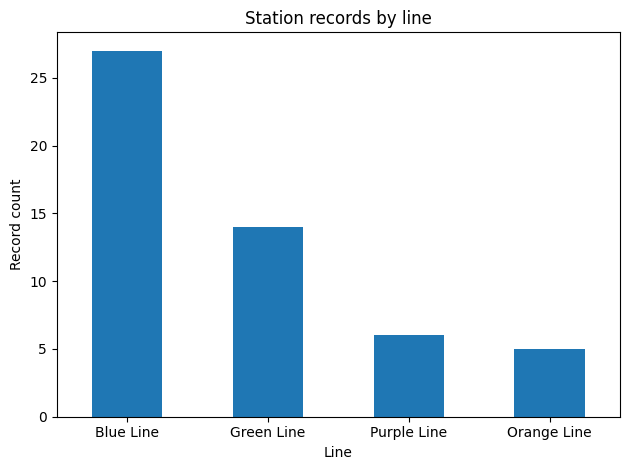

In [8]:
line_summary = (
    df.groupby("Line", dropna=False)
      .agg(
          station_records=("Station ID", "size"),
          distinct_station_names=("Station Name", "nunique"),
          upcoming_records=("Date Status", lambda s: int((s == "Upcoming").sum())),
      )
      .reset_index()
      .sort_values("station_records", ascending=False)
)
display(line_summary)
line_summary.to_csv(REPORTS_DIR / "station_records_by_line.csv", index=False)

ax = line_summary.plot(
    kind="bar", x="Line", y="station_records", legend=False,
    title="Station records by line", rot=0
)
ax.set_xlabel("Line")
ax.set_ylabel("Record count")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "station_records_by_line.png", dpi=160, bbox_inches="tight")
plt.show()


**Interpretation prompt:** State which line has the most records only after running the aggregation. Clarify that record count is not passenger demand, service quality, or necessarily a count of unique physical stations.


## 4. Station layout by line

,Line,Station Layout,station_records
0,Blue Line,At grade,4
1,Blue Line,Elevated,7
2,Blue Line,Underground,16
3,Green Line,Elevated,5
4,Green Line,Underground,9
5,Orange Line,Elevated,5
6,Purple Line,Elevated,6


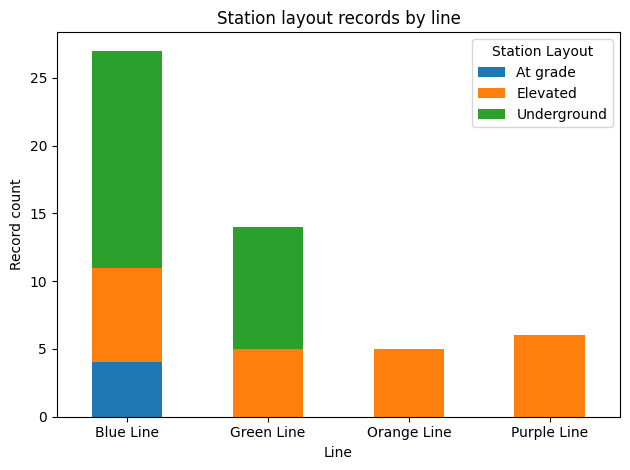

In [9]:
layout_summary = (
    df.groupby(["Line", "Station Layout"], dropna=False)
      .size().reset_index(name="station_records")
)
display(layout_summary)
layout_summary.to_csv(REPORTS_DIR / "station_layout_by_line.csv", index=False)

layout_pivot = layout_summary.pivot(
    index="Line", columns="Station Layout", values="station_records"
).fillna(0)
ax = layout_pivot.plot(kind="bar", stacked=True, title="Station layout records by line")
ax.set_xlabel("Line")
ax.set_ylabel("Record count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "station_layout_by_line.png", dpi=160, bbox_inches="tight")
plt.show()


## 5. Opening date analysis

,Opening Year,station_records
0,1984,2
1,1986,15
2,2009,4
3,2010,2
4,2013,1
5,2020,6
6,2021,2
7,2022,7
8,2024,7


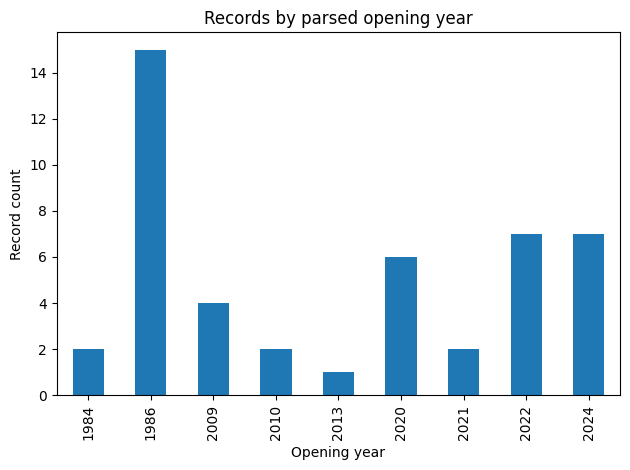

Date status counts:


,records
Date Status,
Parsed,46
Upcoming,6


In [10]:
date_counts = (
    df.loc[df["Date Status"].eq("Parsed")]
      .groupby("Opening Year").size()
      .rename("station_records").reset_index()
      .sort_values("Opening Year")
)
display(date_counts)
date_counts.to_csv(REPORTS_DIR / "parsed_opening_date_counts_by_year.csv", index=False)

if not date_counts.empty:
    date_counts["cumulative_records"] = date_counts["station_records"].cumsum()
    ax = date_counts.plot(
        x="Opening Year", y="station_records", kind="bar", legend=False,
        title="Records by parsed opening year"
    )
    ax.set_xlabel("Opening year")
    ax.set_ylabel("Record count")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "opening_records_by_year.png", dpi=160, bbox_inches="tight")
    plt.show()

print("Date status counts:")
display(df["Date Status"].value_counts(dropna=False).rename_axis("Date Status").to_frame("records"))


**Important limitation:** The source has repeated opening dates, and dates may refer to different extension or opening events. Interpret the chart as counts of dataset records with parseable dates, not a complete official history of the metro network. Confirm dates with a trusted source before publishing historical claims.


## 6. Route distance analysis: validate before interpreting

In [11]:
# Sort by line and distance to create an exploratory spacing measure.
# This assumes each line's distance values describe one ordered segment. Review resets,
# route branches and station order before treating these differences as real adjacent gaps.
distance_data = df.dropna(subset=["Line", "Distance from Start (km)"]).copy()
distance_data = distance_data.sort_values(["Line", "Distance from Start (km)", "Station ID"])
distance_data["Exploratory distance difference (km)"] = (
    distance_data.groupby("Line")["Distance from Start (km)"].diff()
)

spacing_summary = (
    distance_data.groupby("Line")["Exploratory distance difference (km)"]
    .agg(
        number_of_differences="count",
        median_difference_km="median",
        mean_difference_km="mean",
        minimum_difference_km="min",
        maximum_difference_km="max",
    ).reset_index()
)
display(spacing_summary)
spacing_summary.to_csv(REPORTS_DIR / "exploratory_spacing_summary.csv", index=False)

negative_or_zero = distance_data[
    distance_data["Exploratory distance difference (km)"] <= 0
]
print("Non-positive differences to investigate:", len(negative_or_zero))
display(negative_or_zero[[
    "Station ID", "Station Name", "Line", "Distance from Start (km)",
    "Exploratory distance difference (km)"
]])


,Line,number_of_differences,median_difference_km,mean_difference_km,minimum_difference_km,maximum_difference_km
0,Blue Line,26,1.15,1.403846,0.0,2.6
1,Green Line,13,1.20,1.000000,0.0,2.0
2,Orange Line,4,1.75,1.750000,1.5,2.0
3,Purple Line,5,2.00,2.000000,2.0,2.0


Non-positive differences to investigate: 2


,Station ID,Station Name,Line,Distance from Start (km),Exploratory distance difference (km)
26,27,Howrah Maidan,Blue Line,0.0,0.0
33,34,Central Park,Green Line,2.5,0.0


Do not label these values as actual distances between consecutive physical stations until station order and line segments are verified. The current calculation is a diagnostic based on sorted distance values, not route adjacency.


## 7. Geospatial sanity checks

,Station ID,Station Name,Line,Latitude,Longitude,Coordinates in broad Kolkata bounds
0,1,Kavi Subhash,Blue Line,22.4710,88.3773,True
1,2,Shahid Khudiram,Blue Line,22.4673,88.3685,True
2,3,Kavi Nazrul,Blue Line,22.4617,88.3619,True
3,4,Gitanjali,Blue Line,22.4515,88.3525,True
4,5,Masterda Surya Sen,Blue Line,22.4392,88.3412,True
5,6,Netaji,Blue Line,22.4270,88.3300,True
6,7,Mahanayak Uttam Kumar,Blue Line,22.4148,88.3190,True
7,8,Rabindra Sarobar,Blue Line,22.4036,88.3080,True
8,9,Kalighat,Blue Line,22.3945,88.3010,True
9,10,Jatin Das Park,Blue Line,22.3860,88.2950,True


Coordinates outside broad bounds: 0


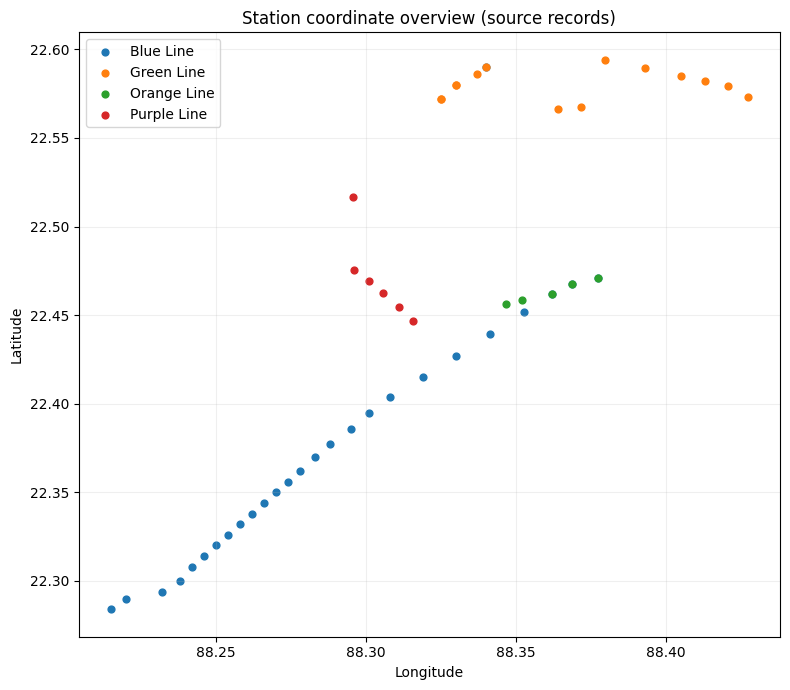

In [12]:
# Broad plausibility bounds for the Kolkata study area, not an official boundary.
geo = df.dropna(subset=["Latitude", "Longitude"]).copy()
geo["Coordinates in broad Kolkata bounds"] = (
    geo["Latitude"].between(22.0, 23.0)
    & geo["Longitude"].between(87.5, 89.0)
)
display(geo[["Station ID", "Station Name", "Line", "Latitude", "Longitude",
             "Coordinates in broad Kolkata bounds"]].head(10))
print("Coordinates outside broad bounds:", int((~geo["Coordinates in broad Kolkata bounds"]).sum()))

fig, ax = plt.subplots(figsize=(8, 7))
for line, group in geo.groupby("Line"):
    ax.scatter(group["Longitude"], group["Latitude"], label=line, s=24)
ax.set_title("Station coordinate overview (source records)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "station_coordinate_overview.png", dpi=160, bbox_inches="tight")
plt.show()


## 8. Findings and recommendations — complete after reviewing outputs

Do not pre-write conclusions. After running the notebook, document three to five findings in `reports/findings.md`, each with:
1. **Evidence:** exact metric, chart or query output.
2. **Interpretation:** what the metric means.
3. **Limitation:** what the current dataset cannot prove.
4. **Next step:** what additional data would validate a broader claim.

Possible next analyses requiring additional data include population-based access coverage, passenger demand, service frequency and transfer-aware network connectivity.


In [13]:
# Final consistency checks before publishing
assert len(df) == len(raw), "Rows were added or removed unexpectedly."
assert "Opening Date Raw" in df.columns
assert "Date Status" in df.columns
print("Final row count:", len(df))
print("Source row count:", len(raw))
print("Row count preserved:", len(df) == len(raw))
print("Outputs written under:", REPORTS_DIR)


Final row count: 52
Source row count: 52
Row count preserved: True
Outputs written under: /content/reports
